# Deck synergy model: card power and pair synergy, one game at a time

This notebook is about the model in `src/openlane/synergy.py` (run for every set by `scripts/deck_synergy.py`).
It learns two things from 17Lands game data:

* **card power**: how much one copy of a card changes the log-odds of winning a game
* **pair synergy**: how much *two cards together* add beyond their separate power

Each example is one game, with the deck registered for that game and the game's context (play/draw, mulligans,
ranks, skill, experience, and the record before the game), so the card and pair values are adjusted for all of
those. `game_model.ipynb` uses the same model to predict the next game; this notebook looks at what it learns
about the cards.

Sections:
1. The model
2. Data
3. Fitting: linear vs synergy, and how many synergy dimensions
4. Card power
5. Pair synergy: the strongest pairs, and how big synergy is next to power
6. Is the synergy real? A split-half test
7. The card map: what the synergy vectors encode
8. Explaining one deck: power + synergy
9. Across 12 sets
10. Linear vs FM vs transformer, trained on draft, sealed, or both
11. Card power in draft vs sealed
12. Takeaways

Needs `data/parquet/MSH.PremierDraft{,.game}.parquet` and, for section 9, `results/*/deck_synergy/results.json`; for sections 10-11,
`data/parquet/MSH.Sealed.game.parquet` and the output of `scripts/deck_synergy_multitask.py MSH`.
The fits run on CPU in about two minutes.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.lines import Line2D
from sklearn.metrics import log_loss, roc_auc_score

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import COLORS, card_metadata
from openlane.deckstrength import (aligned, covariates, experience, flag, game_split, game_win_rates, load_drafts,
                                   record_before, record_onehot)
from openlane.games import game_path
from openlane.synergy import fit

SET, EVENT = "MSH", "PremierDraft"
torch.set_num_threads(6)

# reference categorical palette, fixed order (same as the other notebooks)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(25); pl.Config.set_fmt_str_lengths(40); pl.Config.set_tbl_width_chars(140)

polars.config.Config

## 1. The model

For one game, x is the deck as card counts (lands included) and c is the game's context:

P(win) = σ( b + **w·x** + **Σ<sub>i<j</sub> x<sub>i</sub> x<sub>j</sub> ⟨v<sub>i</sub>, v<sub>j</sub>⟩** + γ·c )

* **w·x** is card power: one number per card, summed over the deck. With only this term the model is a plain
  logistic regression ("linear").
* **The pair term** is a *factorization machine* (FM). Each card gets a short vector v<sub>i</sub> (k = 4 or 16
  numbers), and the synergy of two cards is the dot product of their vectors. A set has about 340 cards, so about
  57,000 pairs. Most pairs are rarely seen together, so a separate weight for each pair would be pure noise. The
  vectors share strength: if A goes with B and B goes with C, A's and C's vectors end up related too.
* **γ·c** adjusts for context, so neither term gets credit for it: play/draw, mulligans, user and opponent rank,
  the user's skill and experience buckets, and the record before the game.

The pair sum looks like it needs every pair, but it has a cheap closed form, which `DeckSYN.deck_score` uses:
Σ<sub>i<j</sub> x<sub>i</sub>x<sub>j</sub>⟨v<sub>i</sub>,v<sub>j</sub>⟩ = ½ ( ‖Σ x<sub>i</sub>v<sub>i</sub>‖² − Σ x<sub>i</sub>²‖v<sub>i</sub>‖² ).
Two copies of the same card don't count as a pair with each other.

In [2]:
# the closed form matches the explicit sum over pairs
rng = np.random.default_rng(0)
x, V_ = rng.integers(0, 3, 12).astype(float), rng.normal(size=(12, 4))
explicit = sum(x[i] * x[j] * V_[i] @ V_[j] for i in range(12) for j in range(i + 1, 12))
closed = 0.5 * (np.sum((x @ V_) ** 2) - np.sum(x[:, None] ** 2 * V_ ** 2))
print(f"explicit pair sum {explicit:.6f}, closed form {closed:.6f}")

explicit pair sum -7.397425, closed form -7.397425


## 2. Data

Every game in the 17Lands game file whose draft is in the draft table, with the deck registered for that game.
Games take their draft's split (first 70% / next 15% / last 15% of drafts by draft time), so the test games are
all from later drafts. The record before each game is counted from the run's earlier games in the file.

In [3]:
t0 = time.time()
d = load_drafts(SET, EVENT)
names = np.array(d.names)
games = pl.read_parquet(game_path(SET, EVENT))
sp = game_split(d, games["draft_id"])
games, sp = games.filter(pl.Series(sp >= 0)), sp[sp >= 0]
X = aligned(games, "deck_", d.names).astype(np.float32)
y = flag(games["won"]).astype(np.int8)
wb, lb, _ = record_before(games)
ctx = np.hstack([covariates(games), experience(games), record_onehot(wb, lb)]).astype(np.float32)
tr, va, te = sp == 0, sp == 1, sp == 2
print(f"{games.height:,} games, {len(names)} cards, {ctx.shape[1]} context columns; "
      f"train / val / test games {tr.sum():,} / {va.sum():,} / {te.sum():,}  [{time.time() - t0:.0f}s]")

377,376 games, 339 cards, 45 context columns; train / val / test games 266,251 / 56,679 / 54,446  [3s]


**What the model sees.** Every model in this notebook (linear, FM, and the transformer in section 10) gets the
same inputs: the deck as one count per card, plus 45 context columns. The context columns sit in a separate
linear term, so the card terms are adjusted for them. The transformer also sees a few facts about each card
(section 10).

In [4]:
from openlane.deckstrength import N_RANKS
feature_groups = [
    ("deck", "copies of each card in the registered deck, basic lands included", len(names)),
    ("play / draw", "+0.5 on the play, -0.5 on the draw", 1),
    ("mulligans", "user mulligans minus opponent mulligans", 1),
    ("skill", "17Lands user game win-rate bucket (centred), and whether it is known", 2),
    ("user rank", "one-hot, bronze to mythic, plus unknown", N_RANKS),
    ("opponent rank", "one-hot, bronze to mythic, plus unknown", N_RANKS),
    ("experience", "user_n_games_bucket one-hot (1, 5, 10, 50, 100 games logged), plus unknown", 6),
    ("record before game", "the run's wins-losses before this game, one-hot 0-0 to 6-2", 21),
]
assert sum(n for *_, n in feature_groups[1:]) == ctx.shape[1]
display(pl.DataFrame(feature_groups, schema=["input", "what it is", "columns"], orient="row"))

input,what it is,columns
str,str,i64
"""deck""","""copies of each card in the registered de…",339
"""play / draw""","""+0.5 on the play, -0.5 on the draw""",1
"""mulligans""","""user mulligans minus opponent mulligans""",1
"""skill""","""17Lands user game win-rate bucket (centr…",2
"""user rank""","""one-hot, bronze to mythic, plus unknown""",7
"""opponent rank""","""one-hot, bronze to mythic, plus unknown""",7
"""experience""","""user_n_games_bucket one-hot (1, 5, 10, 5…",6
"""record before game""","""the run's wins-losses before this game, …",21


## 3. Fitting: linear vs synergy

All fits use Adam with L2 penalties and stop early on validation games (`synergy.fit`). The FM has two knobs:
k, the length of each card's vector, and the L2 penalty on the vectors, which decides how big synergy is allowed
to get. Each is chosen on validation games; the test games are only used for the final numbers.

In [5]:
specs = [("linear", 0, 1e-5, 0), ("linear", 0, 1e-4, 0)]
specs += [(f"fm{k}", k, 1e-5, l2v) for k in (4, 16) for l2v in (1e-4, 1e-3, 1e-2)]
te_idx = np.flatnonzero(te)
rows, models = [], {}
for name, k, l2w, l2v in specs:
    t1 = time.time()
    m, val, predict = fit(X, ctx, y, sp, k, l2w, l2v, log=lambda s: None)
    p = predict(te_idx)
    rows.append({"model": name, "k": k, "l2 power": l2w, "l2 synergy": l2v, "val log loss": round(val, 5),
                 "test log loss": round(log_loss(y[te], p), 5), "test AUC": round(roc_auc_score(y[te], p), 4),
                 "fit (s)": round(time.time() - t1)})
    models[(name, l2w, l2v)] = (m, val)
fits = pl.DataFrame(rows)
display(fits)
best = {fam: min(((key, mv) for key, mv in models.items() if key[0].startswith(fam)), key=lambda t: t[1][1])
        for fam in ("linear", "fm")}
LIN, FM = best["linear"][1][0], best["fm"][1][0]
print("chosen on validation:", best["linear"][0], best["fm"][0])
SYN_KEY = ("fm4", 1e-5, 1e-3)   # the deck_synergy.py setting, used to inspect synergy in sections 4-8
SYN = models[SYN_KEY][0]

model,k,l2 power,l2 synergy,val log loss,test log loss,test AUC,fit (s)
str,i64,f64,f64,f64,f64,f64,i64
"""linear""",0,0.00001,0.0,0.66077,0.65566,0.638,5
"""linear""",0,0.0001,0.0,0.66069,0.6556,0.6382,4
"""fm4""",4,0.00001,0.0001,0.66276,0.65804,0.6327,5
"""fm4""",4,0.00001,0.001,0.66123,0.65618,0.6372,5
"""fm4""",4,0.00001,0.01,0.6608,0.65571,0.6378,7
"""fm16""",16,0.00001,0.0001,0.66873,0.66521,0.6153,2
"""fm16""",16,0.00001,0.001,0.66149,0.65672,0.6362,5
"""fm16""",16,0.00001,0.01,0.66126,0.6562,0.6373,5


chosen on validation: ('linear', 0.0001, 0) ('fm4', 1e-05, 0.01)


**On MSH, validation picks the FM with the heaviest penalty on synergy** (`fm4`, L2 0.01). That shrinks the pair
terms almost to zero, and it ties the linear model (test 0.65571 vs 0.65560). Every FM that is allowed more synergy
does worse, and `fm16` with a light penalty overfits badly (0.6652). So on this set the data find no reliable synergy
beyond card power.

To see what the synergy term picks up when it is allowed to, sections 4-8 use `fm4` with L2 1e-3. That is the
setting `deck_synergy.py` uses, and it is 0.0006 worse than linear on test games.

## 4. Card power

The synergy model's w (`fm4`, L2 1e-3; see the note above), in log-odds per copy. For comparison, the 17Lands-style GIH WR (win rate when the card was in the
opening hand or drawn) from the training games. Cards in at least 2,000 training games.

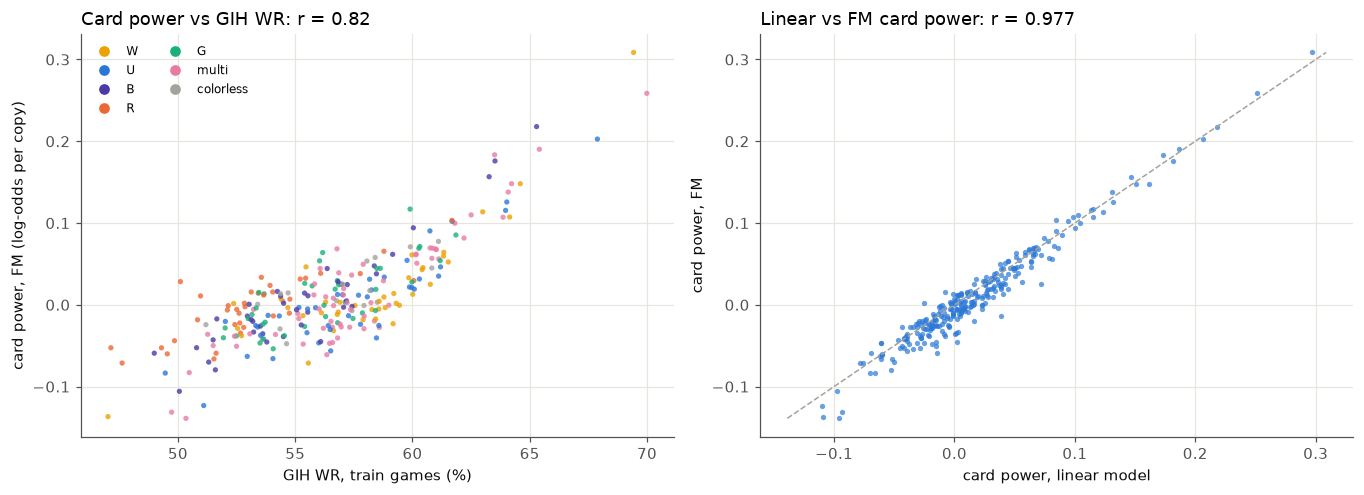

Highest card power


card,colour,power,GIH WR %,train games
str,str,f32,f64,i64
"""Captain Marvel, Earth's Protector""","""W""",0.309,69.4,8091
"""The Super Hero Civil War""","""multi""",0.259,70.0,17374
"""Doctor Doom""","""B""",0.218,65.3,6857
"""Leader, Super-Genius""","""U""",0.203,67.9,17830
"""Jennifer Walters""","""multi""",0.19,65.4,7614
"""The Coming of Galactus""","""multi""",0.183,63.5,6196
"""M.O.D.O.K.""","""B""",0.176,63.5,6611
"""Elektra, Daughter of the Hand""","""B""",0.157,63.3,12669
"""Agent Phil Coulson""","""W""",0.148,64.6,15802


Lowest card power


card,colour,power,GIH WR %,train games
str,str,f32,f64,i64
"""Armor Wars""","""multi""",-0.139,50.3,3030
"""Invisible Woman, Sue Storm""","""W""",-0.137,47.0,5918
"""Madame Hydra""","""multi""",-0.131,49.7,11712
"""Multiversal Incursion""","""U""",-0.123,51.1,3923
"""Construct a Cosmic Cube""","""B""",-0.106,50.1,5337
"""Alien Invasion""","""multi""",-0.083,50.5,6443
"""Rewrite History""","""U""",-0.083,49.5,4744
"""Moonstone, Harsh Mistress""","""B""",-0.08,51.6,11305


In [6]:
meta = card_metadata(list(names), SET)
gih = game_win_rates(games.filter(pl.Series(tr)), list(names))["gih_wr"]
n_train = (X[tr] > 0).sum(0)
common = n_train >= 2000
w_fm, w_lin = SYN.w.detach().numpy(), LIN.w.detach().numpy()

def color_of(i):
    cs = [c for c in COLORS if meta[c][i]]
    return "multi" if len(cs) > 1 else (cs[0] if cs else "colorless")
CCOL = {"W": YELLOW, "U": BLUE, "B": VIOLET, "R": ORANGE, "G": AQUA, "multi": MAGENTA, "colorless": GRAY}
card_color = np.array([color_of(i) for i in range(len(names))])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
a1.scatter(gih[common] * 100, w_fm[common], s=12, c=[CCOL[c] for c in card_color[common]], lw=0, alpha=0.8)
a1.set_xlabel("GIH WR, train games (%)"); a1.set_ylabel("card power, FM (log-odds per copy)")
a1.set_title(f"Card power vs GIH WR: r = {np.corrcoef(gih[common], w_fm[common])[0, 1]:.2f}", loc="left")
a1.legend(handles=[Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in CCOL.items()], fontsize=8, ncol=2)
a2.scatter(w_lin[common], w_fm[common], s=12, color=BLUE, lw=0, alpha=0.7)
lim = [w_fm[common].min(), w_fm[common].max()]
a2.plot(lim, lim, color=GRAY, ls="--", lw=1)
a2.set_xlabel("card power, linear model"); a2.set_ylabel("card power, FM")
a2.set_title(f"Linear vs FM card power: r = {np.corrcoef(w_lin[common], w_fm[common])[0, 1]:.3f}", loc="left")
plt.tight_layout(); plt.show()

power = (pl.DataFrame({"card": names, "colour": card_color, "power": w_fm, "GIH WR %": gih * 100,
                       "train games": n_train})
         .filter(pl.col("train games") >= 2000).with_columns(pl.col("power").round(3), pl.col("GIH WR %").round(1)))
print("Highest card power"); display(power.sort("power", descending=True).head(10))
print("Lowest card power"); display(power.sort("power").head(8))

Card power is the solid part of the model. It tracks GIH WR (r = 0.82), and adding synergy barely changes it (r =
0.977 against the linear model). The top of the list is the set's bombs: Captain Marvel, The Super Hero Civil War,
Doctor Doom and Leader. The two measures differ where a card's win rate comes from the decks it ends up in rather than
the card itself. Power is fitted jointly over the whole deck and the game context, so it doesn't credit those.

Madame Hydra is the lowest-power card that is widely played (-0.13), and it is also in the strongest synergy pair in
the next section. The FM can move value between a card's power and its pairs, which is one sign the pair values are
not well pinned down.

## 5. Pair synergy

The synergy of a pair is ⟨v<sub>i</sub>, v<sub>j</sub>⟩, in log-odds when both are in the deck. Only pairs that
were together in at least 2,000 training games are listed; rarer pairs are mostly the model filling in from
the vectors.

In [7]:
V = SYN.v.detach().numpy()
S = V @ V.T
P = (X[tr] > 0).astype(np.float32)
co = P.T @ P
iu = np.triu_indices(len(names), 1)
ok = co[iu] >= 2000
pairs = (pl.DataFrame({"card a": names[iu[0]][ok], "card b": names[iu[1]][ok], "synergy": S[iu][ok],
                       "games together": co[iu][ok].astype(int)})
         .with_columns(pl.col("synergy").round(4)))
print(f"{pairs.height:,} pairs in ≥2,000 training games")
print("Strongest positive pairs"); display(pairs.sort("synergy", descending=True).head(12))
print("Strongest negative pairs"); display(pairs.sort("synergy").head(12))

8,911 pairs in ≥2,000 training games
Strongest positive pairs


card a,card b,synergy,games together
str,str,f32,i64
"""Madame Hydra""","""Yellowjacket, Heartless Marauder""",0.009,3543
"""Baron Strucker, HYDRA Overlord""","""Yellowjacket, Heartless Marauder""",0.0087,5714
"""Killmonger, Scourge of Wakanda""","""Yellowjacket, Heartless Marauder""",0.0078,3404
"""Klaw, Sonic Subjugator""","""Yellowjacket, Heartless Marauder""",0.0077,6248
"""Baron Strucker, HYDRA Overlord""","""Killmonger, Scourge of Wakanda""",0.0067,3795
"""Bullseye, Death Dealer""","""Killmonger, Scourge of Wakanda""",0.0066,2311
"""HYDRA Assault Robot""","""Yellowjacket, Heartless Marauder""",0.0066,2762
"""Killmonger, Scourge of Wakanda""","""Klaw, Sonic Subjugator""",0.0064,4790
"""Visions of Villainy""","""Yellowjacket, Heartless Marauder""",0.0063,8802


Strongest negative pairs


card a,card b,synergy,games together
str,str,f32,i64
"""Atlantis Attacks""","""Yellowjacket, Heartless Marauder""",-0.0065,2321
"""Bold Biochemist""","""Dependable Quinjet""",-0.006,4174
"""Killmonger, Scourge of Wakanda""","""Take Up the Shield""",-0.0059,2130
"""Web Up""","""Yellowjacket, Heartless Marauder""",-0.0058,2134
"""Ant-Man's Army""","""S.H.I.E.L.D. Spy Kit""",-0.0055,4815
"""Rapid Rescue""","""S.H.I.E.L.D. Spy Kit""",-0.0055,2164
"""S.H.I.E.L.D. Spy Kit""","""Undercover Skrull""",-0.0055,6187
"""Birnin Zana Plaza""","""Knight of Wundagore""",-0.0054,5350
"""Baxter Building""","""S.H.I.E.L.D. Spy Kit""",-0.0052,7109


**How big is synergy next to power?** A single pair is tiny, but a deck has about 250 pairs of distinct nonland
cards. The fair comparison is per deck: across the test games, how much does each deck's *total* card power vary,
and how much does its *total* synergy vary?

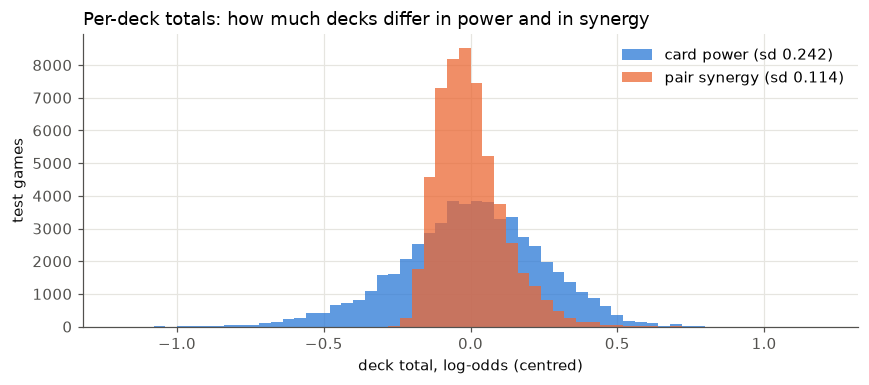

sd of single-pair synergy (pairs in ≥2,000 games): 0.0014; sd of single-card power (≥2,000 games): 0.0589
correlation of deck power and deck synergy: -0.19


In [8]:
Xt = torch.from_numpy(X[te])
with torch.no_grad():
    deck_power = (Xt @ SYN.w).numpy()
    deck_syn = SYN.deck_score(Xt).numpy() - deck_power
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-1.2, 1.2, 61)
ax.hist(deck_power - deck_power.mean(), bins=bins, color=BLUE, alpha=0.75, label=f"card power (sd {deck_power.std():.3f})")
ax.hist(deck_syn - deck_syn.mean(), bins=bins, color=ORANGE, alpha=0.75, label=f"pair synergy (sd {deck_syn.std():.3f})")
ax.set_xlabel("deck total, log-odds (centred)"); ax.set_ylabel("test games"); ax.legend()
ax.set_title("Per-deck totals: how much decks differ in power and in synergy", loc="left")
plt.tight_layout(); plt.show()
print(f"sd of single-pair synergy (pairs in ≥2,000 games): {pairs['synergy'].std():.4f}; "
      f"sd of single-card power (≥2,000 games): {w_fm[common].std():.4f}")
print(f"correlation of deck power and deck synergy: {np.corrcoef(deck_power, deck_syn)[0, 1]:.2f}")

A single pair is about 40× smaller than a single card (sd 0.0014 vs 0.059). But a deck has 200-250 pairs of
distinct cards, so the **per-deck synergy total** varies with sd 0.11, about half the spread of total card power
(0.24). If that spread were real, synergy would matter a lot. The next section tests whether it is.

## 6. Is the synergy real? A split-half test

If the pair values are real, two models trained on *different* drafts should find the same ones. Here the training
drafts are split in two at random, the chosen FM is refitted on each half (same validation games), and the two
halves' values are compared. Card power gets the same test, as a yardstick for what "real" looks like.

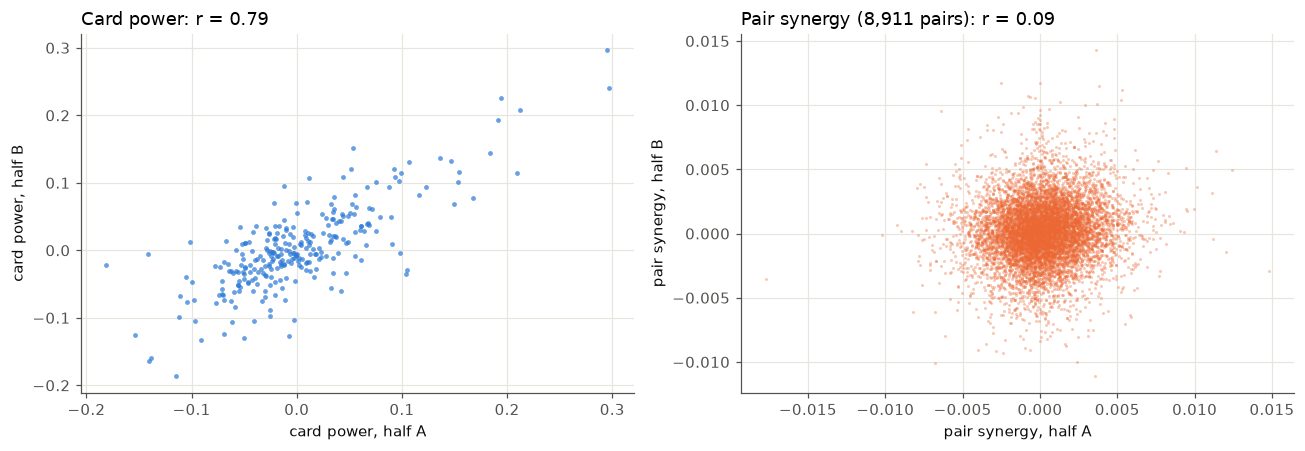

top-50 pairs shared by the two halves: 0 of 50


In [9]:
fm_key = SYN_KEY
draft_half = dict(zip(d.draft_id.tolist(), np.random.default_rng(1).integers(0, 2, len(d.draft_id)).tolist()))
half = np.array([draft_half[x] for x in games["draft_id"].to_list()])
halves = []
for h in (0, 1):
    sp_h = sp.copy()
    sp_h[tr & (half != h)] = -1          # fit ignores rows that are neither 0 (train) nor 1 (val)
    m, _, _ = fit(X, ctx, y, sp_h, int(fm_key[0][2:]), fm_key[1], fm_key[2], log=lambda s: None)
    halves.append(m)
w_h = [m.w.detach().numpy() for m in halves]
S_h = [(m.v.detach().numpy() @ m.v.detach().numpy().T)[iu][ok] for m in halves]
r_power = np.corrcoef(w_h[0][common], w_h[1][common])[0, 1]
r_syn = np.corrcoef(S_h[0], S_h[1])[0, 1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.scatter(w_h[0][common], w_h[1][common], s=10, color=BLUE, lw=0, alpha=0.7)
a1.set_xlabel("card power, half A"); a1.set_ylabel("card power, half B")
a1.set_title(f"Card power: r = {r_power:.2f}", loc="left")
a2.scatter(S_h[0], S_h[1], s=4, color=ORANGE, lw=0, alpha=0.35)
a2.set_xlabel("pair synergy, half A"); a2.set_ylabel("pair synergy, half B")
a2.set_title(f"Pair synergy ({ok.sum():,} pairs): r = {r_syn:.2f}", loc="left")
plt.tight_layout(); plt.show()
top_a = set(np.argsort(-S_h[0])[:50]); top_b = set(np.argsort(-S_h[1])[:50])
print(f"top-50 pairs shared by the two halves: {len(top_a & top_b)} of 50")

**On MSH it isn't real.** Card power replicates across the two halves of the drafts (r = 0.79), but pair synergy
doesn't (r = 0.09), and none of the top 50 pairs show up in both halves' top 50. The per-deck synergy spread in
section 5 is mostly the model fitting noise, which is why validation shrinks it away.

The top pairs in section 5 (Yellowjacket with the HYDRA cards, Killmonger, Klaw) make thematic sense, but at this
data size they can't be told apart from noise. Pair effects of 0.001-0.002 log-odds are tiny next to the noise of a
single game, and each half here has about 130k training games.

## 7. The card map

Synergy is a dot product, so cards with similar vectors go well together and cards with opposite vectors clash.
Projecting the vectors to two dimensions (PCA) gives a map of the set as the model sees it. Colour is the card's
colour identity; only cards in ≥2,000 training games, and the 25 with the longest vectors are labelled.

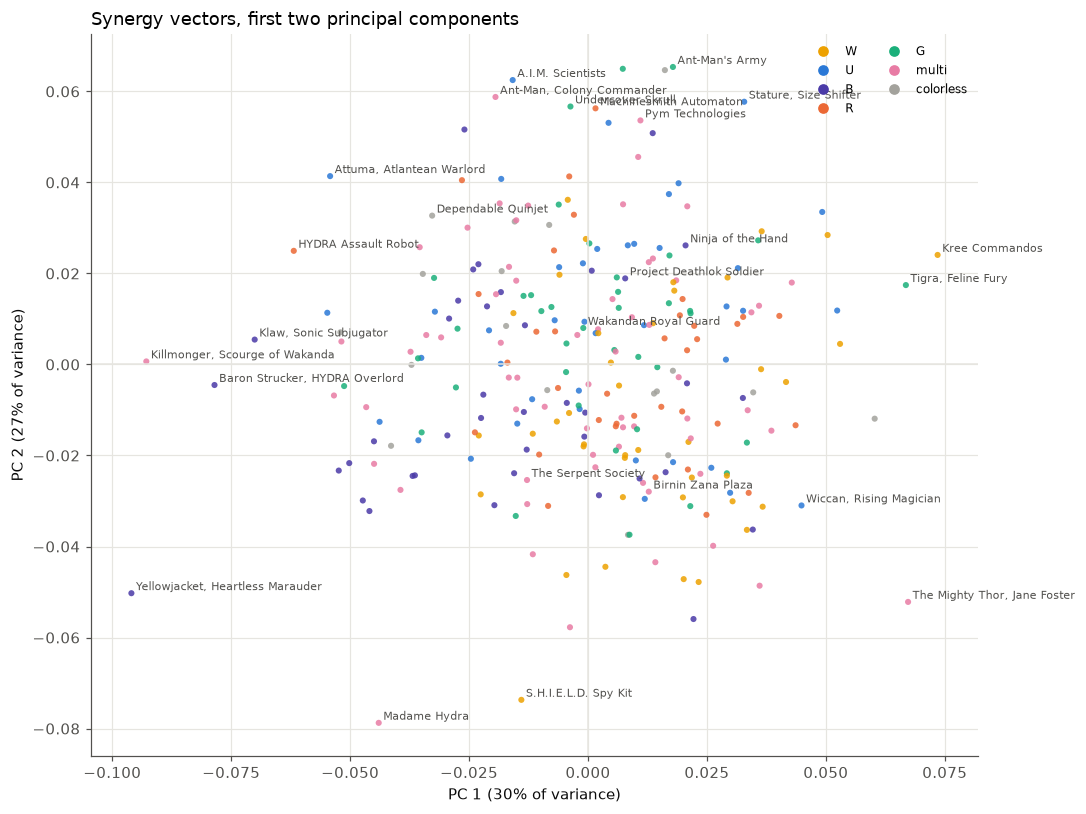

In [10]:
Vc = V[common]
U_, s_, Wt = np.linalg.svd(Vc - Vc.mean(0), full_matrices=False)
xy = (Vc - Vc.mean(0)) @ Wt[:2].T
fig, ax = plt.subplots(figsize=(10, 7.5))
cc = card_color[common]
ax.scatter(xy[:, 0], xy[:, 1], s=16, c=[CCOL[c] for c in cc], lw=0, alpha=0.85)
norm = np.linalg.norm(Vc, axis=1)
for i in np.argsort(-norm)[:25]:
    ax.annotate(names[common][i], xy[i], fontsize=7, color=MUTED, xytext=(3, 2), textcoords="offset points")
ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
ax.set_xlabel(f"PC 1 ({s_[0] ** 2 / (s_ ** 2).sum():.0%} of variance)")
ax.set_ylabel(f"PC 2 ({s_[1] ** 2 / (s_ ** 2).sum():.0%} of variance)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in CCOL.items()], fontsize=8,
          loc="upper right", ncol=2)
ax.set_title("Synergy vectors, first two principal components", loc="left")
plt.tight_layout(); plt.show()

The first component (30% of the variance) pulls one group of black villain cards to the left: Yellowjacket,
Killmonger, Baron Strucker, Klaw and Madame Hydra. That is the one archetype the model sees consistently. Beyond it,
the colours are not clustered, which fits section 6: most of the vector structure is noise.

## 8. Explaining one deck

The model's deck score splits exactly into card terms and pair terms. Below, the test deck with the highest total
synergy: its biggest card contributions, then its best and worst pairs.

In [11]:
def explain_deck(row, k=8):
    xi = X[row]
    idx = np.flatnonzero(xi)
    card = pl.DataFrame({"card": names[idx], "copies": xi[idx].astype(int), "power × copies": w_fm[idx] * xi[idx]})
    a, b = np.triu_indices(len(idx), 1)
    pr = pl.DataFrame({"card a": names[idx[a]], "card b": names[idx[b]],
                       "synergy × copies": S[idx[a], idx[b]] * xi[idx[a]] * xi[idx[b]]})
    tot_p, tot_s = card["power × copies"].sum(), pr["synergy × copies"].sum()
    print(f"{int(xi.sum())} cards, {len(idx)} distinct, {pr.height} pairs. Card power total {tot_p:+.3f}, "
          f"pair synergy total {tot_s:+.3f} log-odds. Won: {bool(y[row])}")
    rnd = lambda df, c: df.with_columns(pl.col(c).round(4))
    display(rnd(card.sort("power × copies", descending=True).head(k), "power × copies"))
    display(rnd(pl.concat([pr.sort("synergy × copies", descending=True).head(k),
                           pr.sort("synergy × copies").head(4)]), "synergy × copies"))

explain_deck(te_idx[np.argmax(deck_syn)])

40 cards, 20 distinct, 190 pairs. Card power total -0.263, pair synergy total +0.927 log-odds. Won: True


card,copies,power × copies
str,i64,f32
"""Doctor Doom""",1,0.2179
"""Ares, God of War""",1,0.0685
"""Widow's Bite""",2,0.0568
"""Baron Strucker, HYDRA Overlord""",2,0.0504
"""Hour of Defeat""",2,0.0496
"""Madame Masque""",1,0.0379
"""Ninja of the Hand""",1,0.0143
"""The Masters of Evil""",1,0.0107


card a,card b,synergy × copies
str,str,f32
"""HYDRA Troopers""","""Swamp""",0.0635
"""Baron Strucker, HYDRA Overlord""","""Swamp""",0.0627
"""Swamp""","""Visions of Villainy""",0.0567
"""Crossbones, Malicious Mercenary""","""Swamp""",0.0537
"""Swamp""","""Yellowjacket, Heartless Marauder""",0.0483
"""Madame Hydra""","""Swamp""",0.0377
"""Agents of HYDRA""","""Swamp""",0.0289
"""Hell's Kitchen""","""Swamp""",0.0273
"""Ninja of the Hand""","""Swamp""",-0.0177


And the test deck with the lowest total synergy:

In [12]:
explain_deck(te_idx[np.argmin(deck_syn)])

40 cards, 21 distinct, 210 pairs. Card power total -0.283, pair synergy total -0.112 log-odds. Won: True


card,copies,power × copies
str,i64,f32
"""Justice, Vance Astrovik""",1,0.1155
"""Cloak and Dagger, Entwined""",1,0.0998
"""Dark Deed""",1,0.0942
"""Cruel Alliance""",1,0.0617
"""Ninja of the Hand""",3,0.043
"""Falcon's Wing Harness""",1,0.0313
"""Hour of Defeat""",1,0.0248
"""Frozen in Ice""",1,0.0182


card a,card b,synergy × copies
str,str,f32
"""Frozen in Ice""","""Island""",0.0187
"""Swamp""","""Visions of Villainy""",0.0181
"""Klaw, Sonic Subjugator""","""Swamp""",0.0172
"""Giant-Sized Flying Ant""","""Island""",0.017
"""Bold Biochemist""","""Island""",0.0131
"""Fisk Tower""","""Swamp""",0.0111
"""Bold Biochemist""","""Rewrite History""",0.0101
"""Island""","""Roxxon Brutes""",0.0099
"""Bold Biochemist""","""Ninja of the Hand""",-0.0413


**What the per-deck synergy actually is: mostly the mana base.** The highest-synergy deck is nearly mono-black, and
its +0.93 log-odds of synergy comes almost entirely from Swamp paired with black cards. Each pair counts once per
copy, so eight Swamps multiply every Swamp pair by eight. The lowest-synergy deck loses on Island × Swamp and on
off-colour pairs.

So the biggest thing the FM learns is that a deck with consistent colours does better than its cards suggest. That is
real, but `deckstrength.ipynb`'s structure features (number of main colours, splash) capture it directly with a
handful of numbers.

## 9. Across 12 sets

`scripts/deck_synergy.py` was run on 12 Premier Draft sets. That run uses only complete drafts' games and has no
record or experience terms, so its numbers differ slightly from the fits above. Two scores:

* **game log loss**: held-out games, FM vs linear (negative = synergy helps)
* **draft Spearman**: the deck score (power, or power + synergy) used to rank test drafts by their W/(W+L), the
  metric used in `deckstrength.ipynb`

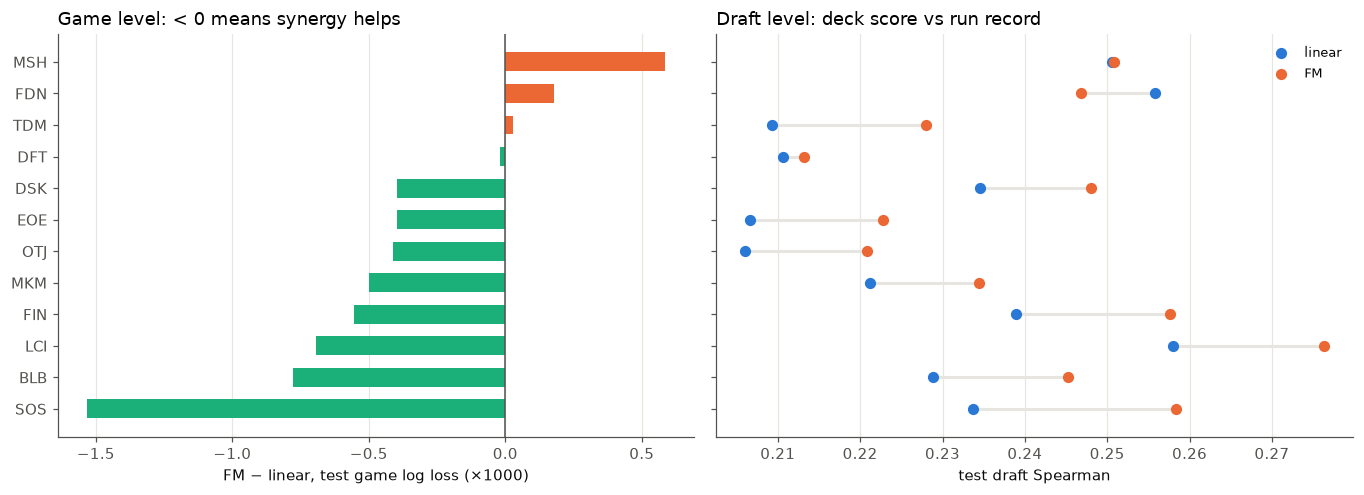

FM better on test games in 9 of 12 sets; mean draft Spearman linear 0.230, FM 0.242


set,best FM,Δ game log loss,Spearman linear,Spearman FM
str,str,f64,f64,f64
"""SOS""","""fm16""",-0.00153,0.234,0.258
"""BLB""","""fm4""",-0.00078,0.229,0.245
"""LCI""","""fm4""",-0.00069,0.258,0.276
"""FIN""","""fm4""",-0.00056,0.239,0.258
"""MKM""","""fm4""",-0.0005,0.221,0.234
"""OTJ""","""fm4""",-0.00041,0.206,0.221
"""EOE""","""fm16""",-0.0004,0.207,0.223
"""DSK""","""fm16""",-0.0004,0.235,0.248
"""DFT""","""fm16""",-0.00002,0.211,0.213


In [13]:
rows = []
for f in sorted(ROOT.glob("results/*.PremierDraft/deck_synergy/results.json")):
    r = json.loads(f.read_text())
    fm_best = min(("fm4", "fm16"), key=lambda n: r[n]["val_logloss"])
    rows.append({"set": f.parent.parent.name.split(".")[0], "best FM": fm_best,
                 "Δ game log loss": r[fm_best]["test_logloss"] - r["linear"]["test_logloss"],
                 "Spearman linear": r["linear"]["draft_spearman"], "Spearman FM": r[fm_best]["draft_spearman"]})
xs = pl.DataFrame(rows).sort("Δ game log loss")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
yy = np.arange(xs.height)
a1.barh(yy, xs["Δ game log loss"] * 1000, color=[AQUA if v < 0 else ORANGE for v in xs["Δ game log loss"]], height=0.6)
a1.axvline(0, color=MUTED, lw=1); a1.set_yticks(yy, xs["set"]); a1.grid(axis="y", visible=False)
a1.set_xlabel("FM − linear, test game log loss (×1000)"); a1.set_title("Game level: < 0 means synergy helps", loc="left")
for i, (l_, f_) in enumerate(zip(xs["Spearman linear"], xs["Spearman FM"])):
    a2.plot([l_, f_], [i, i], color=GRID, lw=2, zorder=1)
a2.scatter(xs["Spearman linear"], yy, color=BLUE, s=40, label="linear", zorder=2)
a2.scatter(xs["Spearman FM"], yy, color=ORANGE, s=40, label="FM", zorder=2)
a2.set_xlabel("test draft Spearman"); a2.legend(fontsize=8.5); a2.grid(axis="y", visible=False)
a2.set_title("Draft level: deck score vs run record", loc="left")
plt.tight_layout(); plt.show()
print(f"FM better on test games in {(xs['Δ game log loss'] < 0).sum()} of {xs.height} sets; "
      f"mean draft Spearman linear {xs['Spearman linear'].mean():.3f}, FM {xs['Spearman FM'].mean():.3f}")
display(xs.with_columns(pl.col("Δ game log loss").round(5), pl.col("Spearman linear").round(3),
                        pl.col("Spearman FM").round(3)))

**MSH is the weakest set for synergy.** Across the 12 sets, the FM beats the linear model on held-out games in 9 and
raises draft Spearman from 0.230 to 0.242 on average. SOS, BLB and LCI gain the most, and MSH gains the least. So
synergy may be easier to detect in other sets, but none of them has had the split-half test yet. Run it before
trusting their pair tables.

## 10. Linear vs FM vs transformer, trained on draft, sealed, or both

**The transformer.** The FM can only add up pairs. A transformer can, in principle, learn anything about a deck
as a whole: three-card packages, curve, how many fixers a splash needs. `synergy.DeckTransformer` reads the deck
as a set of tokens, one per distinct card (about 23 in a typical deck). Each token is the sum of:

* a learned embedding of the card,
* an embedding of its number of copies (basic lands run to 17),
* a small MLP of the card's metadata: colours, rarity, mana value, bonus-sheet flag, and card types (25 numbers).

Two self-attention layers (width 64, 4 heads) mix the tokens, and a CLS token reads out a deck score. The model
also keeps the linear w·x term, so attention only has to learn what card power misses. The context term γ·c is
the same 45 columns as before. **The three models differ only in f(deck).**

**Sealed.** 17Lands also publishes games from Sealed (best-of-one, 7 wins or 3 losses, same 339 cards): 52k
games from 9,040 events, against 377k Premier Draft games. Sealed has no draft table, so events are split by
time the same way (first 70% / next 15% / last 15%). Sealed games have no rank, so those columns read "unknown".
Sealed decks come from a random 6-pack pool rather than a draft, so they are weaker and less focused.

**Three ways to train each model:**

* **draft**: Premier Draft games only (the models above)
* **sealed**: Sealed games only
* **multi**: both. The card terms (w, the FM vectors, the transformer) are shared. Each event gets its own bias,
  its own context weights and its own card power offset dw<sub>event</sub>. The offset has an L2 penalty, so a card's
  power moves away from the shared value only where that event's data insist. Each event's own validation log
  loss counts equally for early stopping and for choosing the penalties.

Every model is scored on both events' test games. The fits take about 27 minutes (the transformers train on
MPS), so they run in `scripts/deck_synergy_multitask.py`, and this section reads its output.

In [14]:
MT = ROOT / f"results/{SET}.{EVENT}/deck_synergy_multitask"
mt = pl.DataFrame(json.loads((MT / "results.json").read_text()))
tp = pl.read_parquet(MT / "test_preds.parquet")
EVS = ("PremierDraft", "Sealed")
show = mt.select("model", "trained on", "config", *[pl.col(f"{e} test {m}").round(5 if m == "logloss" else 4)
                                                   for e in EVS for m in ("logloss", "auc")],
                 pl.col("fit seconds").round(0))
# the card offset penalty l2_dw only exists in the multitask fits
show = show.with_columns(pl.when(pl.col("trained on") != "multi").then(pl.col("config").str.replace(r" l2_dw=\S+", ""))
                         .otherwise(pl.col("config")).alias("config"))
display(show)

model,trained on,config,PremierDraft test logloss,PremierDraft test auc,Sealed test logloss,Sealed test auc,fit seconds
str,str,str,f64,f64,f64,f64,f64
"""linear""","""draft""","""l2_w=0.0001""",0.6556,0.6382,0.62477,0.6716,4.0
"""fm""","""draft""","""k=4 l2_v=0.01""",0.65571,0.6378,0.62514,0.6704,8.0
"""transformer""","""draft""","""d=64 layers=2""",0.65599,0.6372,0.62598,0.6702,542.0
"""linear""","""sealed""","""l2_w=0.0001""",0.67794,0.6024,0.64612,0.6249,1.0
"""fm""","""sealed""","""k=16 l2_v=0.01""",0.67912,0.5996,0.64613,0.6247,1.0
"""transformer""","""sealed""","""d=64 layers=2""",0.67155,0.607,0.64376,0.6322,94.0
"""linear""","""multi""","""l2_w=0.0001 l2_dw=0.01""",0.65613,0.6373,0.62469,0.6698,14.0
"""fm""","""multi""","""k=4 l2_v=0.001 l2_dw=0.01""",0.6565,0.6369,0.62342,0.6717,20.0
"""transformer""","""multi""","""d=64 layers=2 l2_dw=0.01""",0.65598,0.6377,0.62351,0.6732,645.0


**On draft games, linear is still best.** Trained on draft, the transformer reaches 0.65599 test log loss,
against 0.65560 for linear and 0.65571 for the FM. It took 9 minutes to fit, against 4 seconds for linear. On
Premier Draft, at this data size, nothing in a deck beyond card power is reliable enough to predict better.

**On sealed games, the draft data are what matter.** Models trained on Sealed alone score 0.644-0.646. The
linear model trained on *draft* alone scores 0.625 on the same Sealed test games, and its AUC is 0.67 against
0.62-0.63. 36k Sealed training games aren't enough to price 339 cards, and a card's power carries over between
formats. Among the Sealed-only models, the transformer is clearly best (0.6438 against 0.6461). The card
metadata let it share what it learns across similar cards, which matters most when data are scarce.

**Multitask helps Sealed a little, and costs Premier Draft a little.** The chart below compares every model with
linear trained on draft, game by game on the same test games, with 95% intervals.

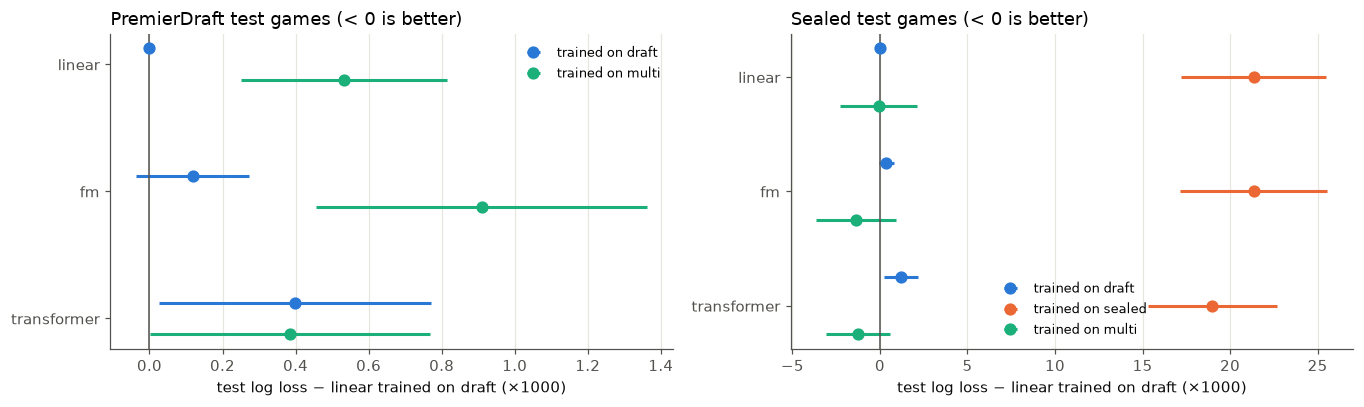

test event,model,trained on,Δ log loss,± 95%
str,str,str,f64,f64
"""PremierDraft""","""fm""","""draft""",0.00012,0.00016
"""PremierDraft""","""linear""","""draft""",0.0,0.0
"""PremierDraft""","""transformer""","""draft""",0.0004,0.00037
"""PremierDraft""","""fm""","""multi""",0.00091,0.00045
"""PremierDraft""","""linear""","""multi""",0.00053,0.00028
"""PremierDraft""","""transformer""","""multi""",0.00038,0.00038
"""PremierDraft""","""fm""","""sealed""",0.02352,0.00186
"""PremierDraft""","""linear""","""sealed""",0.02234,0.00177
"""PremierDraft""","""transformer""","""sealed""",0.01595,0.00151


In [15]:
def nll(y_, p_):
    p_ = np.clip(p_, 1e-7, 1 - 1e-7)
    return -(y_ * np.log(p_) + (1 - y_) * np.log(1 - p_))

FAMS = ("linear", "fm", "transformer")
RCOL = {"draft": BLUE, "sealed": ORANGE, "multi": AQUA}
REGS = {"PremierDraft": ("draft", "multi"), "Sealed": ("draft", "sealed", "multi")}
diff_rows = []
for e in EVS:
    t_ = tp.filter(pl.col("event") == e)
    yy_ = t_["won"].to_numpy()
    base = nll(yy_, t_["linear/draft"].to_numpy())
    for fam in FAMS:
        for reg in ("draft", "sealed", "multi"):
            dl = nll(yy_, t_[f"{fam}/{reg}"].to_numpy()) - base
            diff_rows.append({"test event": e, "model": fam, "trained on": reg, "Δ log loss": dl.mean(),
                              "± 95%": 1.96 * dl.std() / np.sqrt(len(dl))})
diffs = pl.DataFrame(diff_rows)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
for ax, e in zip(axes, EVS):
    regs = REGS[e]
    for j, fam in enumerate(FAMS):
        for k_, reg in enumerate(regs):
            r_ = diffs.filter((pl.col("test event") == e) & (pl.col("model") == fam)
                              & (pl.col("trained on") == reg)).row(0, named=True)
            yv = j + (k_ - (len(regs) - 1) / 2) * 0.25
            ax.errorbar(r_["Δ log loss"] * 1000, yv, xerr=r_["± 95%"] * 1000, fmt="o", color=RCOL[reg], ms=7,
                        elinewidth=2, capsize=0, label=f"trained on {reg}" if j == 0 else None)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(FAMS)), FAMS); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlabel("test log loss − linear trained on draft (×1000)")
    ax.set_title(f"{e} test games (< 0 is better)", loc="left"); ax.legend(fontsize=8.5, loc="best")
plt.tight_layout(); plt.show()
display(diffs.sort("test event", "trained on", "model").with_columns(pl.col("Δ log loss", "± 95%").round(5)))

* **Sealed:** the multitask FM and transformer are the best Sealed models (0.6234 and 0.6235 against 0.6248,
  and the transformer has the best AUC, 0.673). But the gain, 0.0013, is inside its ±0.002 interval: 8k test
  games are not enough to confirm it.
* **Premier Draft:** the multitask models are slightly worse than training on draft alone (linear +0.0005 ±
  0.0003). Early stopping and the penalties are chosen on both events' validation loss, so draft gives up a
  little to fit Sealed better.
* Validation chose the largest offset penalty tried (0.01) for every multitask model. The data want the two
  events to share card power almost completely (section 11).
* Models trained on Sealed alone are 0.016-0.024 worse on draft games, off the left panel's scale. They are in
  the table.

## 11. Card power in draft vs sealed

The linear models' card power, for cards in at least 2,000 draft training games and 1,000 Sealed games.
Left: fitted on each event separately. Right: the multitask model's draft power (w + dw<sub>draft</sub>) against
its Sealed power (w + dw<sub>sealed</sub>).

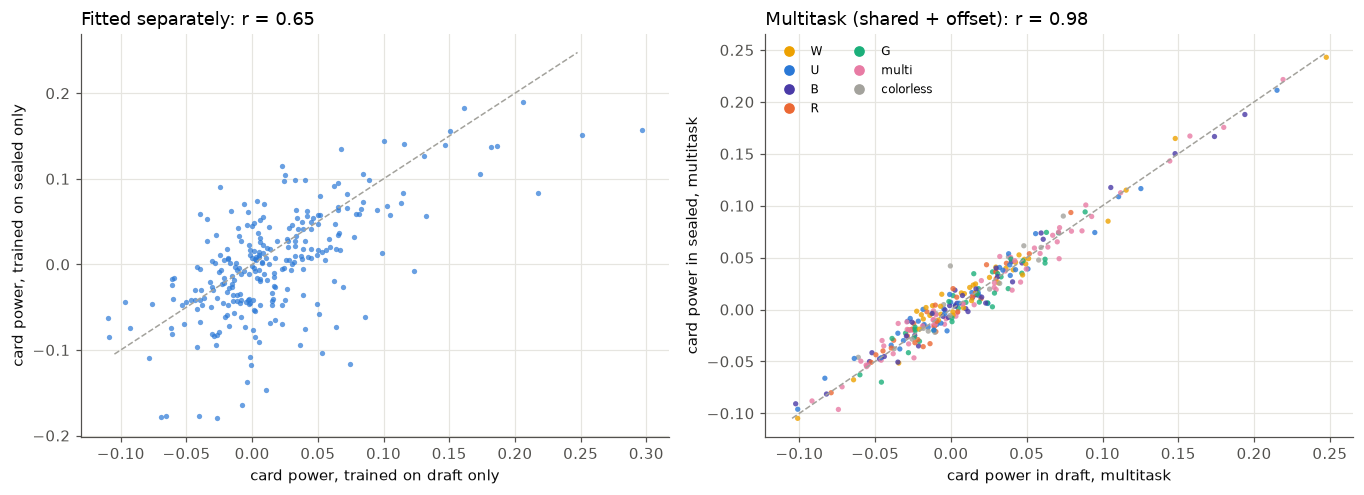

266 cards in ≥2,000 draft training games and ≥1,000 sealed games
Better in sealed than in draft


card,colour,draft,sealed,sealed − draft,sealed games
str,str,f32,f32,f32,i64
"""H.E.R.B.I.E. Scout Unit""","""colorless""",-0.0,0.042,0.042,15794
"""Panther Pounce""","""W""",-0.006,0.015,0.021,3400
"""Plains""","""W""",-0.023,-0.002,0.021,37075
"""Stark Industries""","""multi""",-0.035,-0.013,0.021,4724
"""Speed, Young Avenger""","""R""",0.023,0.043,0.02,1518
"""Giant-Sized Flying Ant""","""U""",-0.018,0.0,0.019,6004


Worse in sealed than in draft


card,colour,draft,sealed,sealed − draft,sealed games
str,str,f32,f32,f32,i64
"""Doc Samson, Super Psychiatrist""","""G""",0.027,0.003,-0.025,2803
"""Claim the Kingdom""","""G""",-0.046,-0.07,-0.024,2307
"""Alien Invasion""","""multi""",-0.074,-0.096,-0.022,1974
"""Hidden Lair""","""multi""",-0.024,-0.047,-0.022,1977
"""The Astonishing Ant-Man""","""multi""",0.04,0.019,-0.022,2283
"""Vision Quest""","""multi""",0.071,0.049,-0.022,1571


In [16]:
cp = pl.read_parquet(MT / "cards.parquet")
n_seal = pl.read_parquet(game_path(SET, "Sealed"), columns=[f"deck_{n}" for n in names])
seal_games = (n_seal.to_numpy() > 0).sum(0)
both = common & (seal_games >= 1000)
wd, ws = cp["w_multi_PremierDraft"].to_numpy(), cp["w_multi_Sealed"].to_numpy()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
a1.scatter(cp["w_draft"].to_numpy()[both], cp["w_sealed"].to_numpy()[both], s=12, color=BLUE, lw=0, alpha=0.7)
r1 = np.corrcoef(cp["w_draft"].to_numpy()[both], cp["w_sealed"].to_numpy()[both])[0, 1]
a1.set_xlabel("card power, trained on draft only"); a1.set_ylabel("card power, trained on sealed only")
a1.set_title(f"Fitted separately: r = {r1:.2f}", loc="left")
a2.scatter(wd[both], ws[both], s=12, c=[CCOL[c] for c in card_color[both]], lw=0, alpha=0.8)
lim = [min(wd[both].min(), ws[both].min()), max(wd[both].max(), ws[both].max())]
for a in (a1, a2):
    a.plot(lim, lim, color=GRAY, ls="--", lw=1)
a2.set_xlabel("card power in draft, multitask"); a2.set_ylabel("card power in sealed, multitask")
a2.legend(handles=[Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in CCOL.items()], fontsize=8, ncol=2)
a2.set_title(f"Multitask (shared + offset): r = {np.corrcoef(wd[both], ws[both])[0, 1]:.2f}", loc="left")
plt.tight_layout(); plt.show()
mv = (pl.DataFrame({"card": names, "colour": card_color, "draft": wd, "sealed": ws, "sealed − draft": ws - wd,
                    "sealed games": seal_games})
      .filter(pl.Series(both)).with_columns(pl.col("draft", "sealed", "sealed − draft").round(3)))
print(f"{both.sum()} cards in ≥2,000 draft training games and ≥1,000 sealed games")
print("Better in sealed than in draft"); display(mv.sort("sealed − draft", descending=True).head(6))
print("Worse in sealed than in draft"); display(mv.sort("sealed − draft").head(6))

Fitted separately, draft and Sealed card power agree only moderately (r = 0.65), mostly because the Sealed fit is
noisy. The multitask model keeps them almost the same (r = 0.98). The per-event offsets have sd 0.010, against
0.053 for card power. So validation finds very little format-specific card power on MSH, and the lists of cards
that move are small effects that haven't been tested for replication (as in section 6).

## 12. Takeaways

1. **Card power is reliable.** It replicates across independent halves of the data (r = 0.79), tracks GIH WR
   (r = 0.82), and is adjusted for play/draw, mulligans, rank, skill, experience and record. These are the per-card
   ratings to use.
2. **On MSH, pair synergy is not reliable.** Validation shrinks it to almost zero, it doesn't replicate across halves
   (r = 0.09), and none of the top 50 pairs recur. Treat the MSH pair tables as hypotheses, not findings.
3. **When synergy is allowed in, it mostly learns the mana base:** basic lands with cards of their colour score
   positive and off-colour pairs negative. Explicit colour and splash features capture this more cheaply.
4. **Other sets look better for synergy** (FM ahead on held-out games in 9 of 12, +0.012 draft Spearman). Next steps:
   - run this split-half test on those sets;
   - fit the FM on nonland cards only, with colour and structure features alongside, so the pair terms have to find
     something other than colour consistency.
5. **A transformer doesn't beat card power on Premier Draft** (0.65599 vs 0.65560 test log loss, at 100× the
   fitting time). It does beat linear and FM when data are scarce (Sealed only), helped by the card metadata.
6. **For Sealed, use the draft data.** A draft-trained model predicts Sealed games far better than a Sealed-trained
   one (0.625 vs 0.646). Multitask training adds a little more on Sealed (−0.0013, not yet significant) and costs a
   little on draft (+0.0005). Card power is nearly the same in both formats.
